In [18]:
import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent))
import fit_lib as fit
import BM29_lib as BM29
import matplotlib.pyplot as plt
import numpy as np
plt.rcParams["text.usetex"] = False
from scipy import optimize
from scipy.optimize import curve_fit

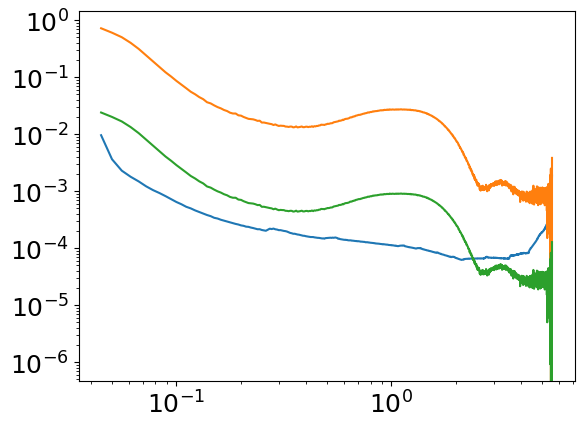

In [45]:
sample = "BIV_S10" # "BIV_S8_15mM_LV4_50uM_aSynWT"
block = sample.split("_")[0]
block_path = BM29.blockpath(block)
dir_names = [x.name for x in block_path.iterdir()]
for dir_name in dir_names:
    if dir_name[:-13].endswith(sample):
        sub_dat_path = block_path / dir_name / "avg_and_sub" / BM29.sample_dict[sample]
        q, I, Ierr = np.loadtxt(sub_dat_path, unpack=True)

plt.loglog(q, Ierr)
plt.loglog(q, I)
plt.loglog(q, I/30)





#### Test Initial Guesses first

In [9]:
# ellipsoidal sym
fit_function = lambda q,  R,  sigma_R,     eps, sigma_eps,  rho_h, sigma_h,    sigma_c,      z_h,    scale: fit.ULV_ellipsoid(q, R,  sigma_R,     eps, sigma_eps,  rho_h, sigma_h,    sigma_c,      z_h,    scale,   0, 0, 0)
plt.close("all")

param_set = "ULV_ellipsoid"

q     = q
I     = I 
I_err = Ierr # np.maximum(I, 0) / 30

# ========================== Parameters ==========================
R = 10.5
sigma_R = 7.13
eps = 0.98
sigma_eps = 0.2
rho_h = 1.6
sigma_h = 0.35
sigma_c = 0.77
z_h = 1.8
scale = 1e-7
c2 = 0
c3 = 0
c4 = 0.007
# [10.471, 7.133, 0.98558, 0.21418, 1.4986, 1.7302,  0.37497,  0.20002,  0.75887, 1.8633, 8.08e-6]
# ========================== Setting Bounds ==============================
# popt = [        R_fit,  sigma_R_fit,     eps_fit, sigma_eps_fit,  rho_h_fit, sigma_h_fit,  sigma_c_fit,      z_h_fit,    scale_fit,   c2_fit,   c3_fit,       c4_fit]
p0           = [        R,  sigma_R,     eps, sigma_eps,  rho_h, sigma_h,    sigma_c,      z_h,    scale] # ,   c2,   c3,       c4]
lower_bounds = [        9,        2,     0.8,         0,      0,     0.2,        0.5,      1.5,  -np.inf] # ,    0,    0,  -np.inf]
upper_bounds = [       25,        9,     1.5,       0.7,     10,     0.5,          1,        2,  +np.inf] # ,  0.2,  0.5,  +np.inf]
#======================== Fit ===========================================
popt, pcov = curve_fit(fit_function, q, I, sigma=I_err, maxfev=1000, p0=p0, bounds = (lower_bounds, upper_bounds))

param_names = fit.param_names.get(param_set)

perr = np.sqrt(np.diag(pcov))
for name, value in zip(param_names, popt):
    globals()[name] = value
chi2, info_text_print = fit.all_info(q, I, I_err, param_names, p0, popt, perr, fit_function, lower_bounds, upper_bounds)
# #=========================== Plot ===========================================

q_fit = q
plt.figure(figsize=(12, 7.5))
plt.errorbar(q, I, I_err, marker="o", markersize=2,markeredgewidth=1,markeredgecolor='Blue', markerfacecolor='None', alpha=0.85, ls="None", label='I_SUB', zorder=1)
plt.loglog(q_fit, fit_function(q_fit, *popt), color='red', label='Fit')
plt.loglog(q_fit, fit_function(q_fit, *p0), color='orange', label='initial guess')

plt.xlabel('$q [1/\\mathrm{nm}]$')
plt.ylabel('$I(q)$')
plt.title(f'{BM29.sample_dict[sample]} using ellip_sym (op. error)')
plt.grid(True)
plt.legend()
legend = plt.legend(loc='center left', bbox_to_anchor=(1, 0.5), alignment='left')
# legend.set_title(info_text_print)

plt.tight_layout()
# plt.savefig(target_folder / f"LV4_{fit_function.__name__}_Jan31.png", bbox_inches='tight', pad_inches=0.05)
plt.show()
info_text="_"
#==================== EDP Plot ==================================================
# fig=fit.EDP_plot(R, sigma_h_fit, sigma_h_fit, sigma_c_fit, rho_h_fit, rho_h_fit, z_h_fit, z_h_fit, info_text, 
#              f'{sample} fac={fac} using {fit_function.__name__}')
fig=fit.EDP_plot(R, sigma_h, sigma_h, sigma_c, rho_h, rho_h, z_h, z_h, "_", 
             f'{BM29.sample_dict[sample]} using ellip_sym (initial guess)')
# fig.savefig(target_folder / f"LV4_EDP_{fit_function.__name__}_FINAL.png", dpi=400, bbox_inches='tight', pad_inches=0.05)

# pow_law_reality_check(c2_fit, c3_fit, c4_fit)


Computing I(q):  12%|██▊                     | 115/1000 [00:01<00:14, 61.67it/s]


KeyboardInterrupt: 

Computing I(q): 100%|████████████████████████| 500/500 [00:03<00:00, 152.40it/s]


NameError: name 'info_text_print' is not defined

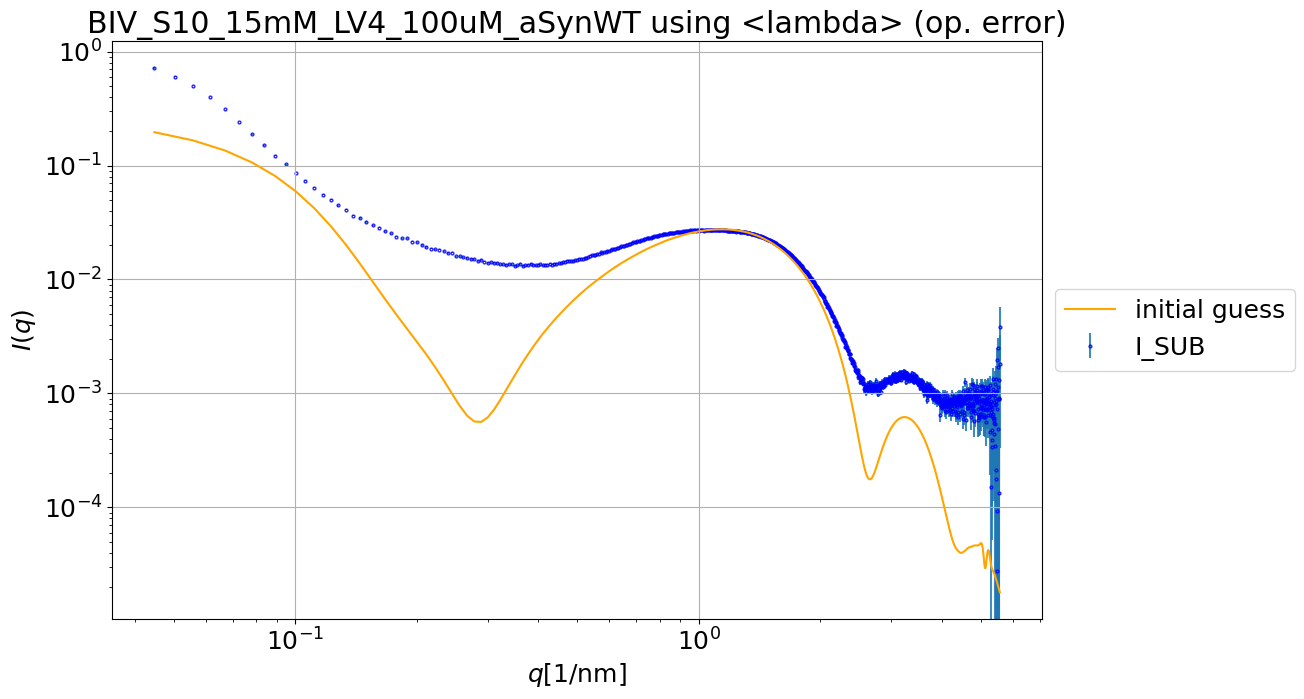

In [10]:
# ellipsoidal asym NO BGR test
fit_function = lambda q,  R,  sigma_R,     eps, sigma_eps,  rho_h1, sigma_h1,  rho_h2, sigma_h2,    sigma_c,      z_h,    scale: fit.ULV_ellipsoid_asym(q, R,  sigma_R,     eps, sigma_eps,  rho_h1, sigma_h1,  rho_h2, sigma_h2,    sigma_c,      z_h,    scale,   0, 0, 0)
plt.close("all")

param_set = "ULV_ellipsoid_asym"

q     = q
I     = I 
I_err = Ierr # np.maximum(I, 0) / 30
I_err_op = np.maximum(I, 0.01) / 30
I_err_op20 = np.maximum(I, 0.01) / 20

thinning = 2
q_thinned = q[::thinning]
I_thinned = I[::thinning]
I_err_thinned = I_err[::thinning]

# ========================== Parameters ==========================
# ======================================================================
R = 10      
sigma_R = 6
eps = 1.13
sigma_eps = 0.1
rho_h1 = 1.88
rho_h2 = 1.04
sigma_h1 = 0.3
sigma_h2 = 0.44
sigma_c = 0.9
z_h = 1.75
scale = 5e-7
# ========================== Setting Bounds ==============================
p0           = [        R,  sigma_R,     eps, sigma_eps,  rho_h1, rho_h2,   sigma_h1, sigma_h2,  sigma_c,      z_h,    scale] # ,   c2,   c3,       c4]
lower_bounds = [        9,        2,     0.8,         0,       0,      0,        0.2,      0.2,      0.5,      1.5,  -np.inf] #,    0,    0,  -np.inf]
upper_bounds = [       25,        9,     1.5,       0.7,      10,     10,        0.5,      0.5,        1,        2,  +np.inf] # ,  0.2,  0.5,  +np.inf]

#======================== Fit ===========================================
# popt, pcov = curve_fit(fit_function, q_thinned, I_thinned, sigma=I_err_thinned, maxfev=1000, p0=p0, bounds = (lower_bounds, upper_bounds))

# param_names = fit.param_names.get(param_set)

# perr = np.sqrt(np.diag(pcov))
# for name, value in zip(param_names, popt):
#     globals()[name] = value
# chi2, info_text_print = fit.all_info(q, I, I_err, param_names, p0, popt, perr, fit_function, lower_bounds, upper_bounds)
# #=========================== Plot ===========================================

q_fit = np.linspace(min(q), max(q), len(q_thinned))
plt.figure(figsize=(12, 7.5))
plt.errorbar(q, I, I_err, marker="o", markersize=2,markeredgewidth=1,markeredgecolor='Blue', markerfacecolor='None', alpha=0.85, ls="None", label='I_SUB', zorder=1)
# plt.loglog(q_fit, fit_function(q_fit, *popt), color='red', label='Fit')
plt.loglog(q_fit, fit_function(q_fit, *p0), color='orange', label='initial guess')
#plt.loglog(q_fit, fit.powerlaw_bgr(q_fit, c2_fit, c3_fit, c4_fit), color='black', label='pow law bgr')
#plt.loglog(q_fit, fit.powerlaw_bgr(q_fit, c2, c3, c4), color='black', label='initial bgr', ls="--")

plt.xlabel('$q [1/\\mathrm{nm}]$')
plt.ylabel('$I(q)$')
plt.title(f'{BM29.sample_dict[sample]} using {fit_function.__name__} (op. error)')
plt.grid(True)
plt.legend()
legend = plt.legend(loc='center left', bbox_to_anchor=(1, 0.5), alignment='left')
legend.set_title(info_text_print)

plt.tight_layout()
# plt.savefig(target_folder / f"LV4_{fit_function.__name__}_FINAL_Jan31.png", bbox_inches='tight', pad_inches=0.05)
plt.show()
info_text="_"
#==================== EDP Plot ==================================================
# fig=fit.EDP_plot(R, sigma_h1_fit, sigma_h2_fit, sigma_c_fit, rho_h1_fit, rho_h2_fit, z_h_fit, z_h_fit, info_text, 
#              f'{BM29.sample_dict[sample]} using {fit_function.__name__}')
# fig.savefig(target_folder / f"LV4_EDP_{fit_function.__name__}_FINAL.png", dpi=400, bbox_inches='tight', pad_inches=0.05)

In [12]:
# ellipsoidal asym NO BGR 
fit_function = lambda q,  R,  sigma_R,     eps, sigma_eps,  rho_h1, sigma_h1,  rho_h2, sigma_h2,    sigma_c,      z_h,    scale: fit.ULV_ellipsoid_asym(q, R,  sigma_R,     eps, sigma_eps,  rho_h1, sigma_h1,  rho_h2, sigma_h2,    sigma_c,      z_h,    scale,   0, 0, 0)
plt.close("all")

param_set = "ULV_ellipsoid_asym"

q     = q
I     = I 
I_err = np.abs(I / 30) #Ierr

thinning = 2
q_thinned = q[::thinning]
I_thinned = I[::thinning]
I_err_thinned = I_err[::thinning]

# ========================== Parameters ==========================
# ======================================================================
R = 10      
sigma_R = 6
eps = 1.13
sigma_eps = 0.1
rho_h1 = 1.88
rho_h2 = 1.04
sigma_h1 = 0.3
sigma_h2 = 0.44
sigma_c = 0.9
z_h = 1.75
scale = 5e-7
# ========================== Setting Bounds ==============================
p0           = [        R,  sigma_R,     eps, sigma_eps,  rho_h1, rho_h2,   sigma_h1, sigma_h2,  sigma_c,      z_h,    scale] # ,   c2,   c3,       c4]
lower_bounds = [        9,        2,     0.8,         0,       0,      0,        0.2,      0.2,      0.5,      1.5,  -np.inf] #,    0,    0,  -np.inf]
upper_bounds = [       25,        9,     1.5,       0.7,      10,     10,        0.5,      0.5,        1,        2,  +np.inf] # ,  0.2,  0.5,  +np.inf]

#======================== Fit ===========================================
popt, pcov = curve_fit(fit_function, q_thinned, I_thinned, sigma=I_err_thinned, maxfev=1000, p0=p0, bounds = (lower_bounds, upper_bounds))

param_names = fit.param_names.get(param_set)

perr = np.sqrt(np.diag(pcov))
for name, value in zip(param_names, popt):
    globals()[name] = value
chi2, info_text_print = fit.all_info(q, I, I_err, param_names, p0, popt, perr, fit_function, lower_bounds, upper_bounds)
# #=========================== Plot ===========================================

q_fit = np.linspace(min(q), max(q), len(q_thinned))
plt.figure(figsize=(12, 7.5))
plt.errorbar(q, I, I_err, marker="o", markersize=2,markeredgewidth=1,markeredgecolor='Blue', markerfacecolor='None', alpha=0.85, ls="None", label='I_SUB', zorder=1)
plt.loglog(q_fit, fit_function(q_fit, *popt), color='red', label='Fit')
plt.loglog(q_fit, fit_function(q_fit, *p0), color='orange', label='initial guess')
#plt.loglog(q_fit, fit.powerlaw_bgr(q_fit, c2_fit, c3_fit, c4_fit), color='black', label='pow law bgr')
#plt.loglog(q_fit, fit.powerlaw_bgr(q_fit, c2, c3, c4), color='black', label='initial bgr', ls="--")

plt.xlabel('$q [1/\\mathrm{nm}]$')
plt.ylabel('$I(q)$')
plt.title(f'{BM29.sample_dict[sample]} using {fit_function.__name__} (op. error)')
plt.grid(True)
plt.legend()
legend = plt.legend(loc='center left', bbox_to_anchor=(1, 0.5), alignment='left')
legend.set_title(info_text_print)

plt.tight_layout()
# plt.savefig(target_folder / f"LV4_{fit_function.__name__}_FINAL_Jan31.png", bbox_inches='tight', pad_inches=0.05)
plt.show()
info_text="_"
#==================== EDP Plot ==================================================
fig=fit.EDP_plot(R, sigma_h1_fit, sigma_h2_fit, sigma_c_fit, rho_h1_fit, rho_h2_fit, z_h_fit, z_h_fit, info_text_print, 
             f'{BM29.sample_dict[sample]} using ellip_asym (op. error)')
# fig.savefig(target_folder / f"LV4_EDP_{fit_function.__name__}_FINAL.png", dpi=400, bbox_inches='tight', pad_inches=0.05)

Computing I(q):  82%|███████████████████▌    | 408/500 [00:03<00:00, 109.48it/s]


KeyboardInterrupt: 

In [ ]:
# ULV_sph_asym_prot_layer
fit_function = lambda q, R, sigma_R, rho_h1, rho_h2, sigma_h1, sigma_h2, sigma_c, z_h, z_h3, sigma_h3, rho_h3, scale: fit.ULV_sph_asym_prot_layer(q, R, sigma_R, rho_h1, rho_h2, sigma_h1, sigma_h2, sigma_c, z_h, z_h3, sigma_h3, rho_h3, scale, 0, 0, 0)

q     = q
I     = I 
I_err = np.abs(I / 30) #Ierr

thinning = 1
q_thinned = q[::thinning]
I_thinned = I[::thinning]
I_err_thinned = I_err[::thinning]

# ========================== Parameters ==========================


# p0=[       R,  sigma_R,     rho_h1,  rho_h2, sigma_h1,  sigma_h2,  sigma_c,      z_h,      z_h3, sigma_h3,    rho_h3,       scale]
p0 = [14.31, 8.624, 0.9992, 3.5, 0.5716, 0.1706, 1.107, 1.794, 3.634, 1.9, 0.04283, 2.628e-07]
p0 = [1.57436844e+01, 7.91272256e+00, 2.83535085e+00, 2.08185239e+00,
       2.41951117e-01, 5.58055672e-01, 1.12082871e+00, 1.72835829e+00,
       3.19168818e+00, 1.89154446e+00, 9.47647302e-01, 6.66105527e-06]


Computing I(q): 100%|██████████████████████| 2000/2000 [00:02<00:00, 762.49it/s]


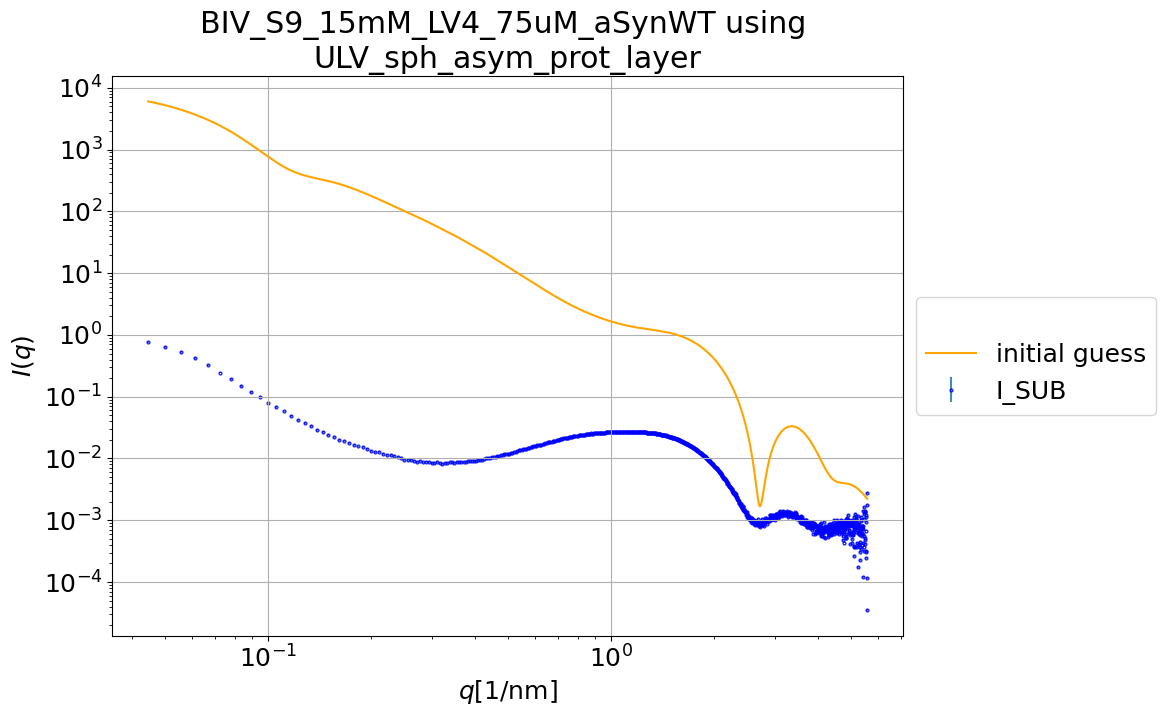

In [52]:
# ========================== Setting Bounds ==============================
# p0           = [        R,  sigma_R,       rho_h1, rho_h2,   sigma_h1, sigma_h2,  sigma_c,      z_h,  z_h3, sigma_h3,   rho_h3,    scale] # ,   c2,   c3,       c4]
lower_bounds = [        9,        2,          0.4,    0.4,        0.1,      0.1,      0.5,      1.5,     2,      0.2,      0.5,  -np.inf] #,    0,    0,  -np.inf]
upper_bounds = [       25,        9,            4,      4,        0.7,      0.7,        1,        2,     5,        1,      2.0,  +np.inf] # ,  0.2,  0.5,  +np.inf]

#======================== Fit ===========================================
# popt, pcov = curve_fit(fit_function, q_thinned, I_thinned, sigma=I_err_thinned, maxfev=10000, p0=p0, bounds = (lower_bounds, upper_bounds))

# param_names = ["R_fit", "sigma_R_fit", "rho_h1_fit", "rho_h2_fit",
#                                 "sigma_h1_fit", "sigma_h2_fit", "sigma_c_fit","z_h_fit", "z_h3_fit", "sigma_h3_fit", "rho_h3_fit", "scale_fit"]

# perr = np.sqrt(np.diag(pcov))
# for name, value in zip(param_names, popt):
#     globals()[name] = value
# chi2, info_text_print = fit.all_info(q, I, I_err, param_names, p0, popt, perr, fit_function, lower_bounds, upper_bounds)
# #=========================== Plot ===========================================

q_fit = np.linspace(min(q), max(q), 2000)
f=plt.figure(figsize=(12, 7.5))
plt.errorbar(q, I, I_err, marker="o", markersize=2,markeredgewidth=1,markeredgecolor='Blue', markerfacecolor='None', alpha=0.85, ls="None", label='I_SUB', zorder=1)
# plt.loglog(q_fit, fit_function(q_fit, *popt), color='red', label='Fit')
plt.loglog(q_fit, fit_function(q_fit, *p0), color='orange', label='initial guess')
#plt.loglog(q_fit, fit.powerlaw_bgr(q_fit, c2_fit, c3_fit, c4_fit), color='black', label='pow law bgr')
#plt.loglog(q_fit, fit.powerlaw_bgr(q_fit, c2, c3, c4), color='black', label='initial bgr', ls="--")

plt.xlabel('$q [1/\\mathrm{nm}]$')
plt.ylabel('$I(q)$')
plt.title(f'{BM29.sample_dict[sample]} using \nULV_sph_asym_prot_layer')
plt.grid(True)
plt.legend()
legend = plt.legend(loc='center left', bbox_to_anchor=(1, 0.5), alignment='left')
info_text_print = " "
legend.set_title(info_text_print)
print(info_text_print)

plt.tight_layout()
# analysis_BM29_July2026 = Path("C:/Users/riko05/Documents/8. SoSe 26/Code/BM29_data_and_analysis_2026/analysis_BM29_July2026")
# target_folder = analysis_BM29_July2026 / "Results_and_Figures" / "Aug18" / f"fit_ULV_sph_asym_prot_layer"
# # plt.savefig(target_folder / f"LV4_{fit_function.__name__}_FINAL_Jan31.png", bbox_inches='tight', pad_inches=0.05)
plt.show()
# info_text="_"
#==================== EDP Plot ==================================================
# fig=fit.EDP_plot(R, sigma_h1, sigma_h2, sigma_c, rho_h1, rho_h2, z_h, z_h, info_text_print,  f'{BM29.sample_dict[sample]} using ellip_asym (op. error)', z_h3, sigma_h3, rho_h3)
# fig.savefig(target_folder / f"LV4_EDP_{fit_function.__name__}_FINAL.png", dpi=400, bbox_inches='tight', pad_inches=0.05)

# f.savefig(target_folder / f"{sample}_ULV_sph_asym_prot_layer_Aug18.png",dpi=400, bbox_inches='tight', pad_inches=0.05)

# fig=fit.EDP_plot(R, sigma_h1, sigma_h2, sigma_c, rho_h1, rho_h2, z_h, z_h, info_text_print,  f'{BM29.sample_dict[sample]} using \nULV_sph_asym_prot_layer ', z_h3, sigma_h3, rho_h3)
# fig.savefig(target_folder / f"EDP_{sample}_ULV_sph_asym_prot_layer_Aug18.png", dpi=400, bbox_inches='tight', pad_inches=0.05)

In [4]:
# ULV_sph_asym_prot_layer + C4
fit_function = lambda q, R, sigma_R, rho_h1, rho_h2, sigma_h1, sigma_h2, sigma_c, z_h, z_h3, sigma_h3, rho_h3, scale, c4: fit.ULV_sph_asym_prot_layer(q, R, sigma_R, rho_h1, rho_h2, sigma_h1, sigma_h2, sigma_c, z_h, z_h3, sigma_h3, rho_h3, scale, 0, 0, c4)

q     = q
I     = I 
I_err = np.abs(I / 30) #Ierr

thinning = 1
q_thinned = q[::thinning]
I_thinned = I[::thinning]
I_err_thinned = I_err[::thinning]

# ========================== Parameters ==========================


# p0=[       R,  sigma_R,     rho_h1,  rho_h2, sigma_h1,  sigma_h2,  sigma_c,      z_h,      z_h3, sigma_h3,    rho_h3,       scale]
p0 = [14.31, 8.624, 0.9992, 3.5, 0.5716, 0.1706, 1.107, 1.794, 3.634, 1.9, 0.04283, 2.628e-07]
p0 = [14.37, 8.609, 0.8, 3.065, 0.4771, 0.1385, 0.7269, 1.863, 4.257, 1.563, 0.03424, 3.026e-07, 0.000419]

Computing I(q): 100%|██████████████████████| 2000/2000 [00:02<00:00, 669.49it/s]


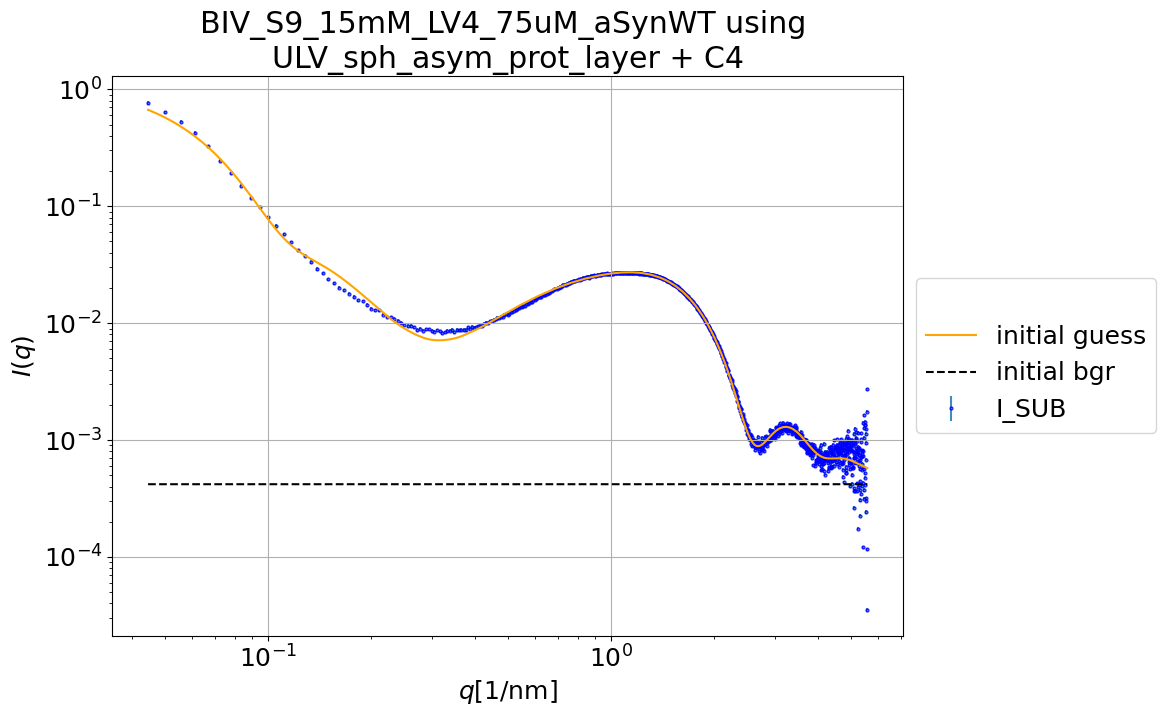

In [5]:
# ========================== Setting Bounds ==============================
# p0           = [        R,  sigma_R,       rho_h1, rho_h2,   sigma_h1, sigma_h2,  sigma_c,      z_h,  z_h3, sigma_h3,   rho_h3,    scale] # ,   c2,   c3,       c4]
lower_bounds = [        9,        2,          0.4,    0.4,        0.1,      0.1,      0.5,      1.5,     2,      0.2,      0.5,  -np.inf] #,    0,    0,  -np.inf]
upper_bounds = [       25,        9,            4,      4,        0.7,      0.7,        1,        2,     5,        1,      2.0,  +np.inf] # ,  0.2,  0.5,  +np.inf]

#======================== Fit ===========================================
# popt, pcov = curve_fit(fit_function, q_thinned, I_thinned, sigma=I_err_thinned, maxfev=10000, p0=p0, bounds = (lower_bounds, upper_bounds))

# param_names = ["R_fit", "sigma_R_fit", "rho_h1_fit", "rho_h2_fit",
#                                 "sigma_h1_fit", "sigma_h2_fit", "sigma_c_fit","z_h_fit", "z_h3_fit", "sigma_h3_fit", "rho_h3_fit", "scale_fit"]

# perr = np.sqrt(np.diag(pcov))
# for name, value in zip(param_names, popt):
#     globals()[name] = value
# chi2, info_text_print = fit.all_info(q, I, I_err, param_names, p0, popt, perr, fit_function, lower_bounds, upper_bounds)
# #=========================== Plot ===========================================

q_fit = np.linspace(min(q), max(q), 2000)
f=plt.figure(figsize=(12, 7.5))
plt.errorbar(q, I, I_err, marker="o", markersize=2,markeredgewidth=1,markeredgecolor='Blue', markerfacecolor='None', alpha=0.85, ls="None", label='I_SUB', zorder=1)
# plt.loglog(q_fit, fit_function(q_fit, *popt), color='red', label='Fit')
plt.loglog(q_fit, fit_function(q_fit, *p0), color='orange', label='initial guess')
#plt.loglog(q_fit, fit.powerlaw_bgr(q_fit, c2_fit, c3_fit, c4_fit), color='black', label='pow law bgr')
plt.loglog(q_fit, fit.powerlaw_bgr(q_fit, 0, 0, p0[-1]), color='black', label='initial bgr', ls="--")

plt.xlabel('$q [1/\\mathrm{nm}]$')
plt.ylabel('$I(q)$')
plt.title(f'{BM29.sample_dict[sample]} using \nULV_sph_asym_prot_layer + C4')
plt.grid(True)
plt.legend()
legend = plt.legend(loc='center left', bbox_to_anchor=(1, 0.5), alignment='left')
info_text_print = " "
legend.set_title(info_text_print)
print(info_text_print)

plt.tight_layout()
# analysis_BM29_July2026 = Path("C:/Users/riko05/Documents/8. SoSe 26/Code/BM29_data_and_analysis_2026/analysis_BM29_July2026")
# target_folder = analysis_BM29_July2026 / "Results_and_Figures" / "Aug18" / f"fit_ULV_sph_asym_prot_layer"
# # plt.savefig(target_folder / f"LV4_{fit_function.__name__}_FINAL_Jan31.png", bbox_inches='tight', pad_inches=0.05)
plt.show()
# info_text="_"
#==================== EDP Plot ==================================================
# fig=fit.EDP_plot(R, sigma_h1, sigma_h2, sigma_c, rho_h1, rho_h2, z_h, z_h, info_text_print,  f'{BM29.sample_dict[sample]} using ellip_asym (op. error)', z_h3, sigma_h3, rho_h3)
# fig.savefig(target_folder / f"LV4_EDP_{fit_function.__name__}_FINAL.png", dpi=400, bbox_inches='tight', pad_inches=0.05)

# f.savefig(target_folder / f"{sample}_ULV_sph_asym_prot_layer_Aug18.png",dpi=400, bbox_inches='tight', pad_inches=0.05)

# fig=fit.EDP_plot(R, sigma_h1, sigma_h2, sigma_c, rho_h1, rho_h2, z_h, z_h, info_text_print,  f'{BM29.sample_dict[sample]} using \nULV_sph_asym_prot_layer ', z_h3, sigma_h3, rho_h3)
# fig.savefig(target_folder / f"EDP_{sample}_ULV_sph_asym_prot_layer_Aug18.png", dpi=400, bbox_inches='tight', pad_inches=0.05)

In [ ]:
# [21.85, 4.561, 1, 3, 0.7, 0.1503, 1.008, 1.76, 9.19e-05]
R = 10
sigma_R = 6              # BEST FROM BM26
rho_h1 = 1.7
rho_h2 = 1.0
sigma_h1 = 0.35
sigma_h2 = 0.5
sigma_c = 0.8
z_h = 1.75
z_h3 = 4
sigma_h3 = 0.7
rho_h3 = 0.7
scale = 5e-7

R = 10
sigma_R = 5.5  # BEST FROM SPHERICAL ASYM FIT
rho_h1 = 1.8
rho_h2 = 1.15
sigma_h1 = 0.3
sigma_h2 = 0.44
sigma_c = 0.5
z_h = 1.76
z_h3 = 2.9
sigma_h3 = 0.3
rho_h3 = 0.5
scale = 5e-7

[13.98, 6.567, 0.8009, 1.848, 0.3318, 0.2703, 0.656, 1.878, 0.0001671, 0.0007208]
R = 14.37 (9, 25)
sigma_R = 8.609 (2, 9)
rho_h1 = 0.8 (0.7, 3.5)
rho_h2 = 3.065 (1, 3.5)
sigma_h1 = 0.4771 (0.13, 0.8)
sigma_h2 = 0.1385 (0.13, 0.8)
sigma_c = 0.7269 (0.5, 1.2)
z_h = 1.863 (1.5, 2)
scale = 3.026e-06 (0, 0.01)
c4 = 0.000419 (0, 1)
chi2_initial = 12271
 
R_fit = 13.98 ± 0.21081
sigma_R_fit = 6.5673 ± 0.091672
rho_h1_fit = 0.80087 ± 0.03559
rho_h2_fit = 1.8479 ± 0.12579
sigma_h1_fit = 0.33175 ± 0.011421
sigma_h2_fit = 0.27031 ± 0.024007
sigma_c_fit = 0.65595 ± 0.023876
z_h_fit = 1.8784 ± 0.012459
scale_fit = 0.00016713 ± 5.7283e-06
c4_fit = 0.00072081 ± 3.6817e-05
chi2 = 16.524


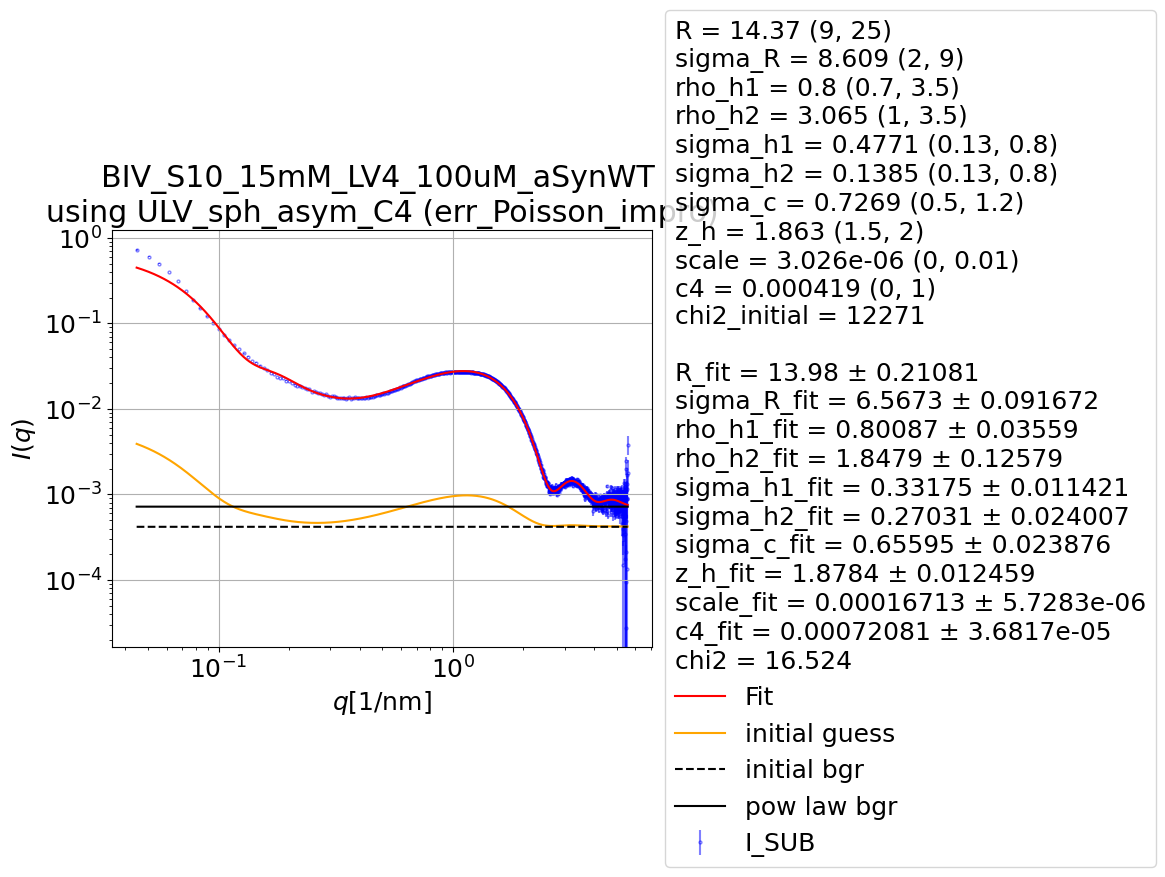

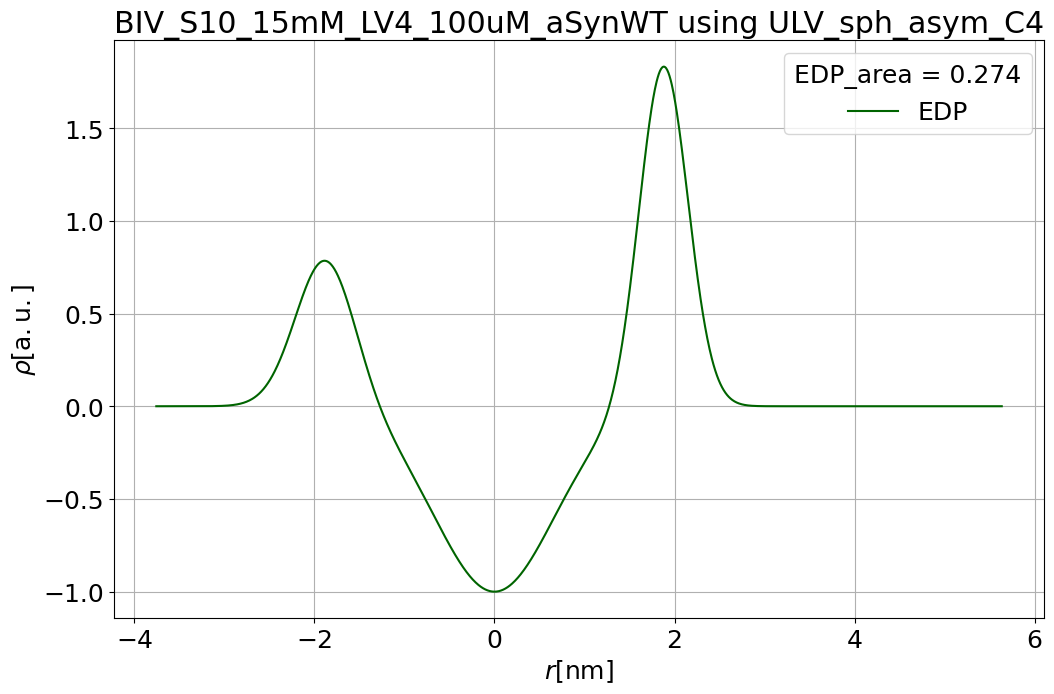

In [50]:
# spherical asym + c4
fit_function = lambda q, R,    sigma_R,   rho_h1,   rho_h2,   sigma_h1,  sigma_h2,  sigma_c,    z_h,   scale, c4: fit.ULV_spheric_asym(q, R,    sigma_R,   rho_h1,   rho_h2,   sigma_h1,  sigma_h2,  sigma_c,    z_h,   scale,      0, 0, c4)
fit_function_name = "ULV_sph_asym_C4"

"""
Iteration 48300, current chi2 = 332.2
Current params:  [13.84263741  7.45905129  1.01586004  1.71244435  0.49757307  0.59267887 0.52259504  1.57056397  0.12634116]
"""
q     = q
I     = I
I_err_Poisson_impro = BM29.op_error_focus_minimum_high(q, Ierr)

# q_mask = q >= 0.1
# I_err[q_mask] = np.abs(I[q_mask] / 15)

# ========================== Parameters ==========================
# R_fit = 14.368 ± 0.27493
# sigma_R_fit = 8.6093 ± 0.12208
# rho_h1_fit = 0.8 ± 0.15285
# rho_h2_fit = 3.0647 ± 6.809
# sigma_h1_fit = 0.47714 ± 0.065725
# sigma_h2_fit = 0.13849 ± 0.31449
# sigma_c_fit = 0.72693 ± 0.042353
# z_h_fit = 1.8629 ± 0.02678
# z_h3_fit = 4.2575 ± 0.18076
# sigma_h3_fit = 1.5631 ± 0.10736
# rho_h3_fit = 0.034245 ± 0.0012611
# scale_fit = 3.026e-07 ± 1.2014e-08
# c4_fit = 0.00041903 ± 0.00050581
# chi2 = 7.2296

# ========================== Setting Bounds ==============================
# p0         = [     R,    sigma_R,   rho_h1,   rho_h2,   sigma_h1,  sigma_h2,  sigma_c,    z_h,       scale,       c4] #,      c2,      c3,      c4]
lower_bounds = [     9,          2,      0.7,        1,        0.13,      0.13,      0.5,    1.5,          0,        0] #,       0,       0, -np.inf]
upper_bounds = [    25,          9,      3.5,      3.5,         0.8,       0.8,      1.2,      2,       1e-2,        1] #,       4,     0.5, +np.inf]
p0           = [ 14.37,      8.609,      0.8,    3.065,      0.4771,    0.1385,   0.7269,  1.863,  3.026e-06, 0.000419]
#======================== Fit ===========================================
popt, pcov = curve_fit(fit_function, q, I, sigma=I_err_Poisson_impro, maxfev=10000, p0=p0, bounds = (lower_bounds, upper_bounds))

param_names = ["R_fit", "sigma_R_fit", "rho_h1_fit", "rho_h2_fit", "sigma_h1_fit", 
               "sigma_h2_fit", "sigma_c_fit", "z_h_fit", "scale_fit", "c4_fit"]

perr = np.sqrt(np.diag(pcov))
fit_lib_entry = "["
for name, value in zip(param_names, popt):
    globals()[name] = value
    fit_lib_entry += f"{value:.4g}, "
fit_lib_entry = fit_lib_entry[:-2]
fit_lib_entry += "]"
print(fit_lib_entry)

chi2, info_text_print = fit.all_info(q, I, BM29.improved_Poisson_error_low_high(q, Ierr), param_names, p0, popt, perr, fit_function, lower_bounds, upper_bounds)
print(info_text_print)

#=========================== Plot ===========================================

q_fit = np.linspace(min(q), max(q), 10000)
plt.figure(figsize=(12, 7.5))
plt.errorbar(q, I, I_err_Poisson_impro, marker="o", markersize=2,markeredgewidth=1,ecolor="Blue", markeredgecolor='Blue', markerfacecolor='None', alpha=0.5, ls="None", label='I_SUB', zorder=1)
plt.loglog(q_fit, fit_function(q_fit, *popt), color='red', label='Fit')
plt.loglog(q_fit, fit_function(q_fit, *p0), color='orange', label='initial guess')        
plt.loglog(q_fit, fit.powerlaw_bgr(q_fit, 0, 0, p0[-1]), color='black', label='initial bgr', ls="--")        
plt.loglog(q_fit, fit.powerlaw_bgr(q_fit, 0, 0, c4_fit), color='black', label='pow law bgr')

plt.xlabel('$q [1/\\mathrm{nm}]$')
plt.ylabel('$I(q)$')
plt.title(f'{BM29.sample_dict[sample]} \nusing {fit_function_name} (err_Poisson_impro)')
plt.grid(True)
legend = plt.legend(loc='center left', bbox_to_anchor=(1, 0.5), alignment='left')
legend.set_title(info_text_print)
plt.tight_layout()
# plt.savefig(target_folder / f"{fit_function.__name__}_op_error2.png",dpi=400, bbox_inches='tight', pad_inches=0.05)
plt.show()

fig=fit.EDP_plot(R_fit, sigma_h1_fit, sigma_h2_fit, sigma_c_fit, rho_h1_fit, rho_h2_fit, z_h_fit, z_h_fit, info_text_print, 
             f'{BM29.sample_dict[sample]} using {fit_function_name}')
# fig.savefig(target_folder / f"LV4_EDP_{fit_function.__name__}_op_error2.png", dpi=400, bbox_inches='tight', pad_inches=0.05)
